### Stromrallye – Lösung Schritt für Schritt

*38. Bundeswettbewerb Informatik (2019/2020), 2. Runde, Aufgabe 1*

Stromrallye ist ein neues Knobelspiel:

Auf einem quadratischen Spielbrett, das in quadratische Felder eingeteilt ist, bewegt sich ein Roboter. Der Roboter hat eine
austauschbare Bordbatterie mit vorgegebener Ladung. Auf einigen Feldern liegen außerdem Ersatzbatterien mit unterschiedlichen
Ladungen. Die Ladungen aller Batterien sind durch ganze Zahlen gegeben.

Der Roboter kann Schritte um ein Feld nach rechts, links, oben oder unten machen. Bei jedem Schritt sinkt die Ladung seiner Batterie um
1. Sinkt die Ladung auf 0, kann er keine weiteren Schritte machen.

Wenn der Roboter auf ein Feld mit einer Ersatzbatterie kommt, muss er seine Bordbatterie gegen die Ersatzbatterie austauschen, selbst
wenn die Ersatzbatterie weniger Ladung hat als die Bordbatterie. Die Ersatzbatterie ist danach die neue Bordbatterie. Nach dem Tausch
muss er das Feld verlassen.

Ziel des Spiels Stromrallye ist es, den Roboter so über das Spielbrett zu bewegen, dass am Ende alle Batterien, einschließlich der
Bordbatterie, entladen sind.

Auf dem Aufgabenblatt steht ein Beispiel auf einem Spielbrett mit 5 × 5 Feldern: der Roboter mit einer Bordbatterie der Ladung 9 und
drei Ersatzbatterien (es ist `stromrallye0.txt`, die Zeichnung folgt in Schritt 1).

#### Aufgabe

a) Schreibe ein Programm, das Stromrallye spielen kann. Es soll zuerst eine Spielsituation einlesen: die Größe des Spielbretts, die
Position des Roboters, die Ladung der Bordbatterie sowie die Positionen und Ladungen der Ersatzbatterien. Danach soll dein Programm
bestimmen, ob die eingelesene Spielsituation lösbar ist, also ob der Roboter sich so bewegen kann, dass am Ende alle Batterien entladen
sind. Wenn ja, soll dein Programm eine entsprechende Folge von Schritten ausgeben.

b) Stromrallye soll auch von Menschen gespielt werden. Schreibe ein Programm, das Spielsituationen erzeugt, die lösbar, aber für einen
menschlichen Spieler schwierig zu lösen sind. Dokumentiere, wie du dein Schwierigkeitsmaß definierst.

*Hinweis:* Zum Ausprobieren kannst du Stromrallye mit einem Damebrett nachspielen. Als Roboter nimmst du einen schwarzen Stein, eine
Batterie mit einer Ladung von n ist ein Stapel aus n + 1 weißen Steinen. Die Bordbatterie wird auf den Roboterstein gestapelt.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `stromrallye0.txt` bis `stromrallye5.txt` (ohne Formatbeschreibung; so lesen wir sie): Zeile 1 enthält
die Größe `n` des Bretts, Zeile 2 den Roboter als `x,y,Ladung`, Zeile 3 die Zahl der Ersatzbatterien, danach jede Ersatzbatterie als
`x,y,Ladung`. Die Koordinaten laufen von 1 bis `n`. Wir lesen `x` als Spalte (von links) und `y` als Zeile (von oben); ein Schritt nach
**unten** erhöht also `y`. Für die Frage, ob eine Situation lösbar ist, spielt diese Wahl keine Rolle.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Backtracking (Tiefensuche):** Man probiert einen Zug, spielt von der neuen Lage aus rekursiv weiter und nimmt den Zug zurück, wenn
  es nicht klappt. Gespeichert wird immer nur die aktuelle Lage und die Liste der gemachten Züge.
- **Breitensuche in Schichten:** Welche Felder erreicht der Roboter mit **genau** 1, 2, 3, … Schritten? Schicht `i + 1` sind die
  Nachbarn der Felder aus Schicht `i`. So findet man alle möglichen Weglängen zwischen zwei Feldern.
- **Abschneiden (Pruning):** Eine schnelle Prüfung, die eine aussichtslose Lage erkennt, bevor man sie durchprobiert. Hier: Gibt es noch
  eine volle Batterie, an die kein Roboter mehr herankommen kann?
- **Sackgassen merken:** Dieselbe Lage kann auf verschiedenen Wegen entstehen. Hat sie einmal nicht zum Ziel geführt, merkt man sie sich
  in einer Menge und probiert sie nicht noch einmal.
- **Manhattan-Abstand:** `|x1 - x2| + |y1 - y2|` ist die kleinste Zahl von Schritten zwischen zwei Feldern, wenn nichts im Weg steht.
- **Zufall für Teil b:** Lösbare Aufgaben erzeugt man am einfachsten **rückwärts**: erst eine Lösung auswürfeln, dann die Ladungen so
  festlegen, dass sie genau passen.

**Nützliche Funktionen und Bibliotheken**
- `dict` mit Feldern `(x, y)` als Schlüssel für die Batterien, `set` für Schichten und gemerkte Lagen, `tuple(...)` macht eine Liste
  zu einem Tupel, das man in eine Menge stecken kann.
- `random.choice`, `random.sample`, `random.Random(zahl)` (ein Zufallsgenerator, der bei gleicher Zahl immer dieselben Zufallszahlen
  liefert).
- `matplotlib.pyplot` zum Zeichnen des Spielbretts.

## Die Idee in Worten

**Die Batteriefelder bleiben immer dieselben.** Kommt der Roboter auf ein Feld mit einer Ersatzbatterie, nimmt er sie und legt seine
Bordbatterie genau dort ab. Auf diesem Feld liegt also wieder eine Batterie, nur eine andere. Die Felder mit Batterien ändern sich
deshalb nie; nur das Startfeld des Roboters ist am Anfang frei (dort liegt keine Batterie). Auch leere Batterien bleiben liegen, und
auch bei ihnen **muss** der Roboter tauschen. Ein Feld mit Batterie ist darum wie eine Tür: Wer darauf tritt, tauscht.

**Züge statt Schritte.** Zwischen zwei Tauschvorgängen läuft der Roboter nur über freie Felder. Wir fassen das zu einem **Zug** zusammen:
vom aktuellen Feld über freie Felder zu einem Batteriefeld, mit `d` Schritten. Danach liegt dort die alte Bordbatterie mit Ladung
`Bordladung - d`, und der Roboter trägt die Batterie, die dort lag. Ein Zug darf auch zurück auf das eigene Feld führen (hinaus und
wieder hinein, mindestens 2 Schritte). Weil die freien Felder sich nie ändern, kann man **vorab** ausrechnen, welche Längen `d` von
jedem Feld zu jedem Batteriefeld möglich sind. Umwege sind wichtig: Mit einem längeren Weg legt man eine Batterie leerer ab.

**Das Ende.** Sind alle abgelegten Batterien leer, muss der Roboter nur noch seine Bordbatterie leer laufen, also genau so viele
Schritte machen, wie sie Ladung hat (auf das letzte Feld darf auch eine leere Batterie, dann ist er fertig).

**Die Suche.** Eine Lage besteht aus dem Feld des Roboters, der Bordladung und den Ladungen der liegenden Batterien. Von jeder Lage aus
probieren wir alle Züge zu Batterien mit Ladung (eine leere Batterie aufzunehmen hilft nicht: danach steht der Roboter still) und jede
mögliche Länge. Das ist Backtracking. Damit es schnell genug wird, kommen zwei Abkürzungen dazu: eine Prüfung, ob noch jede volle
Batterie erreichbar ist, und eine Menge der Lagen, die schon gescheitert sind.

**Eine nützliche Beobachtung:** Jeder Schritt verbraucht genau eine Ladungseinheit, und beim Tauschen geht keine verloren. Eine Lösung hat
deshalb immer genau so viele Schritte, wie am Anfang Ladung da ist (Bordbatterie plus alle Ersatzbatterien).

## Schritt 1: Einlesen und Zeichnen

`lies` gibt die Brettgröße `n`, das Startfeld des Roboters, die Ladung der Bordbatterie und ein Dictionary `batterien` (Feld → Ladung)
zurück.

In [ ]:
import os


def lies(dateiname):
    with open(dateiname) as f:
        zeilen = [zeile.strip() for zeile in f if zeile.strip()]
    n = int(zeilen[0])
    x, y, ladung = zeilen[1].split(',')
    start = (int(x), int(y))
    bord = int(ladung)
    batterien = {}
    for zeile in zeilen[3:3 + int(zeilen[2])]:
        bx, by, ladung = zeile.split(',')
        batterien[(int(bx), int(by))] = int(ladung)
    return n, start, bord, batterien


def datei(nr):
    return os.path.join('beispieldaten', 'stromrallye%d.txt' % nr)


for nr in range(6):
    n, start, bord, batterien = lies(datei(nr))
    gesamt = bord + sum(batterien.values())
    print('stromrallye%d.txt: %d x %d, Roboter auf %s mit %d, %d Ersatzbatterien, Ladung insgesamt %d' %
          (nr, n, n, start, bord, len(batterien), gesamt))

stromrallye0.txt: 5 x 5, Roboter auf (3, 5) mit 9, 3 Ersatzbatterien, Ladung insgesamt 17
stromrallye1.txt: 10 x 10, Roboter auf (1, 1) mit 1, 99 Ersatzbatterien, Ladung insgesamt 100
stromrallye2.txt: 11 x 11, Roboter auf (6, 6) mit 2, 120 Ersatzbatterien, Ladung insgesamt 242
stromrallye3.txt: 14 x 14, Roboter auf (3, 5) mit 9, 3 Ersatzbatterien, Ladung insgesamt 28
stromrallye4.txt: 100 x 100, Roboter auf (40, 25) mit 20, 0 Ersatzbatterien, Ladung insgesamt 20
stromrallye5.txt: 20 x 20, Roboter auf (10, 15) mit 20, 34 Ersatzbatterien, Ladung insgesamt 90


`stromrallye1.txt` und `stromrallye2.txt` sind ganz mit Batterien gefüllt (bis auf das Feld des Roboters), `stromrallye4.txt` hat gar
keine Ersatzbatterie. `zeichne` malt ein Brett: Batterien als Quadrate mit ihrer Ladung, den Roboter als Kreis mit der Bordladung.
Wenn man Züge mitgibt, kommen Pfeile dazu (mit der Zahl der Schritte); ein Zug zurück auf das eigene Feld wird als kleiner Bogen
gezeichnet.

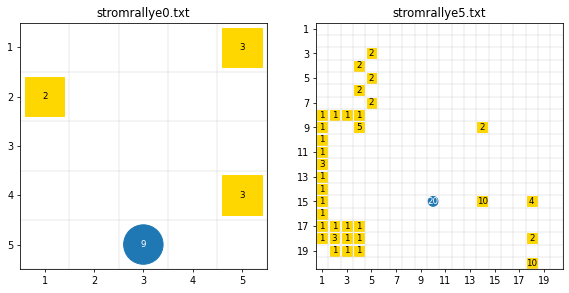

In [ ]:
import matplotlib.pyplot as plt


def zeichne(achse, n, start, bord, batterien, zuege=(), titel=''):
    achse.set_xlim(0.5, n + 0.5)
    achse.set_ylim(n + 0.5, 0.5)                  # y wächst nach unten
    achse.set_aspect('equal')
    achse.set_xticks(range(1, n + 1, max(1, n // 10)))
    achse.set_yticks(range(1, n + 1, max(1, n // 10)))
    for i in range(n + 1):
        achse.plot([i + 0.5, i + 0.5], [0.5, n + 0.5], color='lightgray', lw=0.5)
        achse.plot([0.5, n + 0.5], [i + 0.5, i + 0.5], color='lightgray', lw=0.5)
    for (x, y), ladung in batterien.items():
        achse.add_patch(plt.Rectangle((x - 0.4, y - 0.4), 0.8, 0.8, color='gold' if ladung else 'lightgray'))
        achse.text(x, y, str(ladung), ha='center', va='center', fontsize=9)
    achse.add_patch(plt.Circle(start, 0.4, color='tab:blue'))
    achse.text(start[0], start[1], str(bord), ha='center', va='center', color='white', fontsize=9)
    for nummer, (s, t, d) in enumerate(zuege):
        if s == t:
            achse.annotate('', xy=(t[0] + 0.1, t[1] - 0.3), xytext=(s[0] - 0.1, s[1] - 0.3),
                           arrowprops=dict(arrowstyle='->', color='tab:red', connectionstyle='arc3,rad=-2.5'))
            achse.text(s[0], s[1] - 0.75, str(d), color='tab:green', ha='center', fontsize=8)
        else:
            achse.annotate('', xy=t, xytext=s, arrowprops=dict(arrowstyle='->', color='tab:red',
                                                               connectionstyle='arc3,rad=0.15'))
            achse.text((s[0] + t[0]) / 2 + 0.15, (s[1] + t[1]) / 2 - 0.15, str(d), color='tab:green', fontsize=8)
    achse.set_title(titel)


fig, achsen = plt.subplots(1, 2, figsize=(10, 5))
zeichne(achsen[0], *lies(datei(0)), titel='stromrallye0.txt')
zeichne(achsen[1], *lies(datei(5)), titel='stromrallye5.txt')
plt.show()

## Schritt 2: Welche Weglängen sind möglich?

Von einem Feld `s` aus bilden wir **Schichten**: `frei[i]` sind die freien Felder, die der Roboter mit genau `i` Schritten erreicht,
ohne unterwegs auf ein Batteriefeld zu treten; `ankunft[i]` sind die Batteriefelder, auf denen er nach genau `i` Schritten ankommt (und
tauscht). Schicht `i + 1` entsteht aus den Nachbarn der Felder in `frei[i]`. Ein Feld darf in mehreren Schichten vorkommen, denn der
Roboter darf auch hin und her laufen.

In [ ]:
RICHTUNGEN = {'R': (1, 0), 'L': (-1, 0), 'U': (0, 1), 'O': (0, -1)}


def nachbarn(feld, n):
    x, y = feld
    erg = []
    for dx, dy in RICHTUNGEN.values():
        if 1 <= x + dx <= n and 1 <= y + dy <= n:
            erg.append((x + dx, y + dy))
    return erg


def schichten(s, n, batterien, bis):
    frei = [{s}]
    ankunft = [set()]
    for i in range(1, bis + 1):
        neu_frei, neu_ankunft = set(), set()
        for u in frei[-1]:
            for v in nachbarn(u, n):
                if v in batterien:
                    neu_ankunft.add(v)
                else:
                    neu_frei.add(v)
        frei.append(neu_frei)
        ankunft.append(neu_ankunft)
    return frei, ankunft


def alle_laengen(n, start, batterien, bis):
    """laengen[s][t] = Liste aller möglichen Zuglängen bis 'bis' von Feld s zum Batteriefeld t."""
    laengen = {}
    for s in list(batterien) + [start]:
        frei, ankunft = schichten(s, n, batterien, bis)
        tabelle = {}
        for i in range(1, bis + 1):
            for t in sorted(ankunft[i]):
                if t not in tabelle:
                    tabelle[t] = []
                tabelle[t].append(i)
        laengen[s] = tabelle
    return laengen


n0, start0, bord0, batterien0 = lies(datei(0))
laengen0 = alle_laengen(n0, start0, batterien0, 9)
for s in [start0, (5, 4)]:
    for t in sorted(laengen0[s]):
        print('von', s, 'nach', t, ':', laengen0[s][t])

von (3, 5) nach (1, 2) : [5, 7, 9]
von (3, 5) nach (5, 1) : [6, 8]
von (3, 5) nach (5, 4) : [3, 5, 7, 9]
von (5, 4) nach (1, 2) : [6, 8]
von (5, 4) nach (5, 1) : [3, 5, 7, 9]
von (5, 4) nach (5, 4) : [2, 4, 6, 8]


Vom Startfeld `(3, 5)` aus kommt der Roboter nach `(5, 4)` mit 3, 5, 7 oder 9 Schritten. Zwei Dinge fallen auf:

- Auf einem Schachbrettmuster wechselt jeder Schritt die Farbe. Darum haben alle Weglängen zwischen zwei Feldern dieselbe Gerade/Ungerade-
  Eigenschaft wie der Manhattan-Abstand.
- Hat ein Weg mindestens 3 Schritte, gibt es unterwegs zwei freie Felder hintereinander. Dort kann der Roboter einmal zurück und wieder
  vor gehen und den Weg so um 2, 4, 6, … verlängern. Nur ganz kurze Wege (1 oder 2 Schritte) lassen sich manchmal nicht verlängern.

Zurück auf das eigene Feld `(5, 4)` geht es mit 2 Schritten (hinaus und wieder hinein), mit 4, 6 oder 8.

## Schritt 3: Ein Schiedsrichter

Bevor wir suchen, schreiben wir eine Funktion, die eine Schrittfolge wie `'ORRUL'` genau nach den Regeln nachspielt. Mit ihr prüfen wir
später jede gefundene Lösung. Sie gibt `'gelöst'` zurück oder sagt, was schiefgeht.

In [ ]:
def spiele(n, start, bord, batterien, schritte):
    liegt = dict(batterien)
    feld, ladung = start, bord
    for i in range(len(schritte)):
        if ladung == 0:
            return 'Bordbatterie leer vor Schritt %d' % (i + 1)
        dx, dy = RICHTUNGEN[schritte[i]]
        feld = (feld[0] + dx, feld[1] + dy)
        if not (1 <= feld[0] <= n and 1 <= feld[1] <= n):
            return 'Schritt %d führt vom Brett' % (i + 1)
        ladung -= 1
        if feld in liegt:                         # tauschen
            liegt[feld], ladung = ladung, liegt[feld]
    if ladung > 0 or max(list(liegt.values()) + [0]) > 0:
        return 'nicht alle Batterien leer'
    return 'gelöst'


# die Züge aus den Lösungshinweisen für stromrallye0.txt, von Hand in Schritte übersetzt
print(spiele(n0, start0, bord0, batterien0, 'ORR' + 'OOO' + 'UUU' + 'LLLLOO' + 'UO'))
print(spiele(n0, start0, bord0, batterien0, 'ORR' + 'OOO' + 'LLLL'))
print(spiele(n0, start0, bord0, batterien0, 'RRRRR'))

gelöst
Bordbatterie leer vor Schritt 10
Schritt 3 führt vom Brett


Die Lösung aus den Hinweisen geht so: zur Batterie `(5, 4)` (legt dort 6 ab), weiter zu `(5, 1)` (legt 0 ab), zurück zu `(5, 4)` (legt 0 ab
und nimmt die 6), mit 6 Schritten zu `(1, 2)` (legt 0 ab und nimmt 2) und zum Schluss einen Schritt hinunter und wieder hinauf.

## Schritt 4: Backtracking über Züge

`suche(feld, bord)` probiert von der aktuellen Lage aus alle Züge. Die Ladungen der liegenden Batterien stehen in `ladung` und werden
beim Zurücknehmen eines Zuges wiederhergestellt. Die Reihenfolge der Versuche: zuerst die Züge, bei denen die abgelegte Batterie **leer**
wird, danach die mit wenig Restladung. Eine leere Batterie muss man nie wieder besuchen; das ist meistens ein guter Zug (diese Reihenfolge
empfehlen auch die Lösungshinweise).

Damit die Suche nicht ewig läuft, zählen wir die Aufrufe von `suche` und brechen nach `grenze` Aufrufen ab. Das Ergebnis ist dann `True`
(lösbar, die Züge stehen in `zuege`), `False` (sicher nicht lösbar, alles durchprobiert) oder `None` (Grenze erreicht, wir wissen es
nicht).

In [ ]:
class GrenzeErreicht(Exception):
    pass


def endlauf_moeglich(feld, bord, n, batterien):
    """Kann der Roboter von feld aus genau bord Schritte laufen, ohne vorher auf ein Batteriefeld zu treten?"""
    if bord == 0:
        return True
    frei, ankunft = schichten(feld, n, batterien, bord)
    return len(frei[bord]) > 0 or len(ankunft[bord]) > 0


def loese_v1(n, start, bord, batterien, grenze):
    ladung = dict(batterien)
    bis = max([bord] + list(batterien.values()))    # mehr Ladung hat keine Batterie
    laengen = alle_laengen(n, start, batterien, bis)
    zuege = []
    aufrufe = [0]                                    # Liste, damit suche den Wert ändern kann

    def suche(feld, bord):
        aufrufe[0] += 1
        if aufrufe[0] > grenze:
            raise GrenzeErreicht()
        if max(ladung.values(), default=0) == 0:      # nur noch die Bordbatterie leer laufen
            return endlauf_moeglich(feld, bord, n, batterien)
        moeglich = []
        for t in laengen[feld]:
            if ladung[t] > 0:
                for d in laengen[feld][t]:
                    if d <= bord:
                        moeglich.append((bord - d, d, t))     # (Restladung der abgelegten Batterie, Länge, Ziel)
        moeglich.sort()
        for rest, d, t in moeglich:
            alt = ladung[t]
            ladung[t] = rest
            zuege.append((feld, t, d))
            if suche(t, alt):
                return True
            zuege.pop()                                # Zug zurücknehmen
            ladung[t] = alt
        return False

    try:
        ergebnis = suche(start, bord)
    except GrenzeErreicht:
        ergebnis = None
    return ergebnis, zuege, aufrufe[0]

Damit wir die Versionen der Suche vergleichen können, ohne jedes Mal die Testschleife neu zu schreiben, ruft `teste` immer die Funktion
`loese` auf. Die zeigt erst auf `loese_v1` und später auf die verbesserten Versionen.

In [ ]:
GRENZE = 100000


def loese(n, start, bord, batterien, grenze):
    return loese_v1(n, start, bord, batterien, grenze)


def teste(nummern):
    ergebnisse = {}
    for nr in nummern:
        n, start, bord, batterien = lies(datei(nr))
        ergebnis, zuege, aufrufe = loese(n, start, bord, batterien, GRENZE)
        if ergebnis is None:
            text = '?  (nach %d Aufrufen abgebrochen)' % GRENZE
        elif ergebnis:
            text = 'lösbar, %d Züge, %d Aufrufe' % (len(zuege), aufrufe)
        else:
            text = 'nicht lösbar, %d Aufrufe' % aufrufe
        print('stromrallye%d.txt: %s' % (nr, text))
        ergebnisse[nr] = (ergebnis, zuege, aufrufe)
    return ergebnisse


ergebnisse_v1 = teste([0, 1, 3, 4, 5])

stromrallye0.txt: lösbar, 4 Züge, 37 Aufrufe
stromrallye1.txt: lösbar, 99 Züge, 100 Aufrufe
stromrallye3.txt: nicht lösbar, 298 Aufrufe
stromrallye4.txt: lösbar, 0 Züge, 1 Aufrufe
stromrallye5.txt: ?  (nach 100000 Aufrufen abgebrochen)


Die kleinen Beispiele sind sofort erledigt. `stromrallye1.txt` ist ein 10 × 10-Brett voller Batterien mit Ladung 1: Jeder Zug geht
genau ein Feld weit, und der Roboter muss jedes Feld genau einmal besuchen. Die erste Reihenfolge der Versuche (Felder nach ihren
Koordinaten sortiert) läuft Spalte für Spalte in Schlangenlinien und ist sofort fertig. Bei `stromrallye4.txt` gibt es keine
Ersatzbatterie; der Roboter läuft einfach 20 Schritte.

Bei `stromrallye5.txt` reichen 100000 Aufrufe nicht. Die Suche probiert immer wieder aussichtslose Fortsetzungen. `stromrallye2.txt`
lassen wir hier noch weg (dazu Schritt 8).

## Schritt 5: Unerreichbare Batterien erkennen

Eine Batterie mit Ladung muss irgendwann besucht werden. Dazu muss der Roboter mit einer Batterie, die genug Ladung hat, zu ihr hinlaufen.
Wir zeichnen einen Pfeil von Batterie `a` zu Batterie `b`, wenn die Ladung von `a` mindestens so groß ist wie der Manhattan-Abstand
der beiden Felder. Die Bordbatterie gehört dazu (auf dem Feld des Roboters). Jede Batterie mit Ladung muss **über Pfeile von der
Bordbatterie aus** erreichbar sein, sonst ist die Lage aussichtslos.

Warum gilt das, auch wenn die Batterien später an andere Stellen wandern? Bei einem Zug verliert die getragene Batterie Ladung und landet
auf dem Zielfeld; von dort reicht sie nicht weiter als vorher vom Ausgangsfeld (der Weg dorthin hat ja schon Ladung gekostet; hier
brauchen wir den Manhattan-Abstand, für den Umwege über ein Zwischenfeld nie kürzer sind). Neue Pfeile zeigen nur auf die abgelegte
Batterie, und zwar von denselben Batterien, die vorher auf die aufgenommene gezeigt haben. Was von der Bordbatterie aus nicht erreichbar
ist, wird es also nie mehr. Die Lösungshinweise begründen das ausführlicher (Abschnitt 1.2.3.1).

Die Prüfung ist eine Tiefensuche auf diesen Pfeilen: ein Stapel mit den schon erreichten Batterien (Feld und Ladung), von denen aus wir
nach weiteren suchen.

In [ ]:
def alle_erreichbar(feld, bord, ladung):
    rest = set()
    for f in ladung:
        if ladung[f] > 0:
            rest.add(f)
    stapel = [(feld, bord)]
    while stapel and rest:
        (x, y), l = stapel.pop()
        neu = [f for f in rest if abs(f[0] - x) + abs(f[1] - y) <= l]
        for f in neu:
            rest.remove(f)
            stapel.append((f, ladung[f]))
    return len(rest) == 0


def loese_v2(n, start, bord, batterien, grenze):
    ladung = dict(batterien)
    bis = max([bord] + list(batterien.values()))
    laengen = alle_laengen(n, start, batterien, bis)
    zuege = []
    aufrufe = [0]

    def suche(feld, bord):
        aufrufe[0] += 1
        if aufrufe[0] > grenze:
            raise GrenzeErreicht()
        if max(ladung.values(), default=0) == 0:
            return endlauf_moeglich(feld, bord, n, batterien)
        if not alle_erreichbar(feld, bord, ladung):     # neu: aussichtslos
            return False
        moeglich = []
        for t in laengen[feld]:
            if ladung[t] > 0:
                for d in laengen[feld][t]:
                    if d <= bord:
                        moeglich.append((bord - d, d, t))
        moeglich.sort()
        for rest, d, t in moeglich:
            alt = ladung[t]
            ladung[t] = rest
            zuege.append((feld, t, d))
            if suche(t, alt):
                return True
            zuege.pop()
            ladung[t] = alt
        return False

    try:
        ergebnis = suche(start, bord)
    except GrenzeErreicht:
        ergebnis = None
    return ergebnis, zuege, aufrufe[0]


def loese(n, start, bord, batterien, grenze):
    return loese_v2(n, start, bord, batterien, grenze)


ergebnisse_v2 = teste([0, 1, 3, 4, 5])

stromrallye0.txt: lösbar, 4 Züge, 13 Aufrufe
stromrallye1.txt: lösbar, 99 Züge, 100 Aufrufe
stromrallye3.txt: nicht lösbar, 23 Aufrufe
stromrallye4.txt: lösbar, 0 Züge, 1 Aufrufe
stromrallye5.txt: nicht lösbar, 13038 Aufrufe


Jetzt ist auch `stromrallye5.txt` entschieden: **nicht lösbar**, nach etwa 13000 Aufrufen. Bei `stromrallye3.txt` sinkt die Zahl der
Aufrufe von 298 auf 23. Dort liegt die Batterie mit Ladung 10 auf `(5, 12)` weit weg von den anderen: Nur die Bordbatterie (9, Abstand
genau 9) reicht am Anfang bis dorthin. Sobald der Roboter einen anderen Zug macht, ist sie unerreichbar, und die Prüfung schlägt an.

## Schritt 6: Sackgassen merken

Dieselbe Lage (Feld des Roboters, Bordladung, Ladungen aller liegenden Batterien) kann über verschiedene Zugfolgen entstehen. Wir
speichern jede Lage, aus der es nicht weiterging, als Tupel in der Menge `gescheitert` und brechen ab, wenn sie wieder auftaucht. Die
Ladungen kommen als `tuple(ladung.values())` in den Schlüssel; die Reihenfolge der Felder im Dictionary ändert sich nie, also passt das.

Mit dem Parameter `erreichbar` können wir die Prüfung aus Schritt 5 abschalten, um zu sehen, was jede Idee allein bringt.

In [ ]:
def loese_v3(n, start, bord, batterien, grenze, erreichbar=True):
    ladung = dict(batterien)
    bis = max([bord] + list(batterien.values()))
    laengen = alle_laengen(n, start, batterien, bis)
    zuege = []
    aufrufe = [0]
    gescheitert = set()

    def suche(feld, bord):
        aufrufe[0] += 1
        if aufrufe[0] > grenze:
            raise GrenzeErreicht()
        if max(ladung.values(), default=0) == 0:
            return endlauf_moeglich(feld, bord, n, batterien)
        lage = (feld, bord, tuple(ladung.values()))
        if lage in gescheitert:                           # neu: schon einmal gescheitert
            return False
        if erreichbar and not alle_erreichbar(feld, bord, ladung):
            gescheitert.add(lage)
            return False
        moeglich = []
        for t in laengen[feld]:
            if ladung[t] > 0:
                for d in laengen[feld][t]:
                    if d <= bord:
                        moeglich.append((bord - d, d, t))
        moeglich.sort()
        for rest, d, t in moeglich:
            alt = ladung[t]
            ladung[t] = rest
            zuege.append((feld, t, d))
            if suche(t, alt):
                return True
            zuege.pop()
            ladung[t] = alt
        gescheitert.add(lage)
        return False

    try:
        ergebnis = suche(start, bord)
    except GrenzeErreicht:
        ergebnis = None
    return ergebnis, zuege, aufrufe[0]


n5, start5, bord5, batterien5 = lies(datei(5))
nur_merken5 = loese_v3(n5, start5, bord5, batterien5, GRENZE, erreichbar=False)
print('stromrallye5.txt nur mit Merken:', nur_merken5[0], nur_merken5[2], 'Aufrufe')


def loese(n, start, bord, batterien, grenze):
    return loese_v3(n, start, bord, batterien, grenze)


ergebnisse_v3 = teste([0, 1, 3, 4, 5])

stromrallye5.txt nur mit Merken: None 100001 Aufrufe
stromrallye0.txt: lösbar, 4 Züge, 13 Aufrufe
stromrallye1.txt: lösbar, 99 Züge, 100 Aufrufe
stromrallye3.txt: nicht lösbar, 23 Aufrufe
stromrallye4.txt: lösbar, 0 Züge, 1 Aufrufe
stromrallye5.txt: nicht lösbar, 6316 Aufrufe


Allein hilft das Merken bei `stromrallye5.txt` nicht (nach 100000 Aufrufen keine Entscheidung). Zusammen mit der Erreichbarkeitsprüfung
halbiert es die Zahl der Aufrufe ungefähr. Damit sind alle Beispiele außer `stromrallye2.txt` entschieden.

## Schritt 7: Die Schrittfolge ausgeben

Die Suche liefert Züge `(von, nach, Länge)`. Die Aufgabe verlangt aber Schritte. `weg_genau` findet mit den Schichten aus Schritt 2
einen Weg mit genau `d` Schritten: Wir gehen vom Ziel rückwärts und nehmen in jeder Schicht ein Feld, das neben dem schon gewählten liegt
(das kleinste, damit es eindeutig ist). Ohne Ziel (`ziel=None`) ist es der Endlauf, der irgendwo aufhören darf.

In [ ]:
def weg_genau(s, ziel, d, n, batterien):
    frei, ankunft = schichten(s, n, batterien, d)
    if ziel is None:
        ziel = min(frei[d] | ankunft[d])
    weg = [ziel]
    for i in range(d - 1, -1, -1):
        weg.append(min(u for u in frei[i] if weg[-1] in nachbarn(u, n)))
    weg.reverse()
    return weg


def richtungen(weg):
    namen = {}
    for name in RICHTUNGEN:
        namen[RICHTUNGEN[name]] = name
    text = ''
    for i in range(len(weg) - 1):
        text += namen[(weg[i + 1][0] - weg[i][0], weg[i + 1][1] - weg[i][1])]
    return text


def zeige_loesung(n, start, bord, batterien, zuege, zeilen=10):
    liegt = dict(batterien)
    ladung = bord
    alle = ''
    for i in range(len(zuege)):
        s, t, d = zuege[i]
        schritte = richtungen(weg_genau(s, t, d, n, batterien))
        alle += schritte
        if i < zeilen:
            print('Zug %d: %s -> %s, Länge %d: %s, legt %d ab, nimmt %d auf' %
                  (i + 1, s, t, d, schritte, ladung - d, liegt[t]))
        liegt[t], ladung = ladung - d, liegt[t]
    if len(zuege) > zeilen:
        print('... insgesamt %d Züge' % len(zuege))
    if ladung > 0:
        feld = zuege[-1][1] if zuege else start
        schritte = richtungen(weg_genau(feld, None, ladung, n, batterien))
        alle += schritte
        print('Endlauf, Länge %d: %s' % (ladung, schritte))
    if len(alle) > 60:
        print('Schrittfolge:', alle[:60], '...')
    else:
        print('Schrittfolge:', alle)
    print('%d Schritte, Schiedsrichter: %s' % (len(alle), spiele(n, start, bord, batterien, alle)))
    return alle


schrittfolgen = {}
for nr in [0, 1, 4]:
    print('stromrallye%d.txt' % nr)
    n, start, bord, batterien = lies(datei(nr))
    schrittfolgen[nr] = zeige_loesung(n, start, bord, batterien, ergebnisse_v3[nr][1], zeilen=5)
    print()

stromrallye0.txt
Zug 1: (3, 5) -> (5, 4), Länge 3: ORR, legt 6 ab, nimmt 3 auf
Zug 2: (5, 4) -> (5, 1), Länge 3: OOO, legt 0 ab, nimmt 3 auf
Zug 3: (5, 1) -> (5, 4), Länge 3: UUU, legt 0 ab, nimmt 6 auf
Zug 4: (5, 4) -> (1, 2), Länge 6: LLLLOO, legt 0 ab, nimmt 2 auf
Endlauf, Länge 2: OU
Schrittfolge: ORROOOUUULLLLOOOU
17 Schritte, Schiedsrichter: gelöst

stromrallye1.txt
Zug 1: (1, 1) -> (1, 2), Länge 1: U, legt 0 ab, nimmt 1 auf
Zug 2: (1, 2) -> (1, 3), Länge 1: U, legt 0 ab, nimmt 1 auf
Zug 3: (1, 3) -> (1, 4), Länge 1: U, legt 0 ab, nimmt 1 auf
Zug 4: (1, 4) -> (1, 5), Länge 1: U, legt 0 ab, nimmt 1 auf
Zug 5: (1, 5) -> (1, 6), Länge 1: U, legt 0 ab, nimmt 1 auf
... insgesamt 99 Züge
Endlauf, Länge 1: L
Schrittfolge: UUUUUUUUUROOOOOOOOORUUUUUUUUUROOOOOOOOORUUUUUUUUUROOOOOOOOOR ...
100 Schritte, Schiedsrichter: gelöst

stromrallye4.txt
Endlauf, Länge 20: LLLLLLLLLLLLLLLLLLLL
Schrittfolge: LLLLLLLLLLLLLLLLLLLL
20 Schritte, Schiedsrichter: gelöst



Für `stromrallye0.txt` findet die Suche dieselben Züge wie die Lösungshinweise; nur der Endlauf geht erst hinauf und dann wieder
hinunter (`OU`, auf das Feld mit der leeren Batterie). Bei `stromrallye1.txt` läuft der Roboter in
Schlangenlinien (erst die Spalte `x = 1` hinunter), bei `stromrallye4.txt` einfach 20 Schritte nach links. Der Schiedsrichter bestätigt
alle drei. Die Zeichnung zu `stromrallye0.txt`:

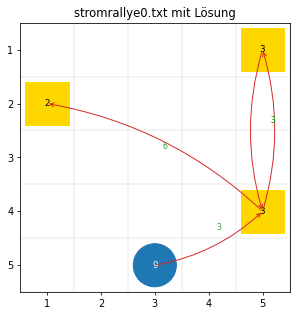

In [ ]:
fig, achse = plt.subplots(figsize=(5, 5))
zeichne(achse, n0, start0, bord0, batterien0, ergebnisse_v3[0][1], titel='stromrallye0.txt mit Lösung')
plt.show()

## Schritt 8: `stromrallye2.txt` – Nachdenken statt Rechnen

Ein 11 × 11-Brett, auf jedem Feld eine Batterie mit Ladung 2, nur in der Mitte steht der Roboter (ebenfalls mit 2). Unsere Suche gibt
hier auf:

In [ ]:
ergebnisse_v3.update(teste([2]))

stromrallye2.txt: ?  (nach 100000 Aufrufen abgebrochen)


Es gibt riesig viele Zugfolgen, und die meisten führen erst sehr spät in eine Sackgasse. Auch die Lösungshinweise schreiben, dass dieses
Beispiel vermutlich nur mit einem besonderen Verfahren gelöst werden kann, und erwarten von einer Einsendung nicht, dass die allgemeine
Suche es schafft. Sie beschreiben aber eine Lösung, die man von Hand findet:

1. Spiralförmig von der Mitte nach außen laufen, jedes Mal ein Feld weit. Bei jedem Schritt legt der Roboter eine Batterie mit 1 ab und
   nimmt eine mit 2 auf.
2. Am Ende der Spirale einen Schritt zurück und wieder vor. Jetzt liegt überall 1 (nur das Feld am Ende ist leer), und der Roboter trägt 1.
3. Die Spirale rückwärts nach innen laufen, jedes Mal ein Feld weit, und dabei alles leeren; der letzte Schritt geht auf das freie
   Mittelfeld.

Wir bauen diese Schrittfolge und lassen sie vom Schiedsrichter prüfen. Die Spirale geht 1 nach rechts, 1 nach unten, 2 nach links,
2 nach oben, 3 nach rechts usw.; Felder außerhalb des Bretts lassen wir weg (das passiert erst ganz am Ende).

In [ ]:
def spirale(n, mitte):
    x, y = mitte
    felder = []
    laenge = 1
    folge = ['R', 'U', 'L', 'O']
    nummer = 0
    while len(felder) < n * n - 1:
        for _ in range(2):                         # je zwei Richtungen mit derselben Länge
            dx, dy = RICHTUNGEN[folge[nummer % 4]]
            for _ in range(laenge):
                x, y = x + dx, y + dy
                if 1 <= x <= n and 1 <= y <= n:
                    felder.append((x, y))
            nummer += 1
        laenge += 1
    return felder


n2, start2, bord2, batterien2 = lies(datei(2))
sp = spirale(n2, start2)
hinaus = richtungen([start2] + sp)
zurueck_vor = richtungen([sp[-1], sp[-2], sp[-1]])
hinein = richtungen(list(reversed(sp)) + [start2])
schritte2 = hinaus + zurueck_vor + hinein
print('Spirale mit', len(sp), 'Feldern, endet auf', sp[-1])
print('Schrittfolge:', schritte2[:40], '...')
print(len(schritte2), 'Schritte, Schiedsrichter:', spiele(n2, start2, bord2, batterien2, schritte2))

Spirale mit 120 Feldern, endet auf (11, 1)
Schrittfolge: RULLOORRRUUULLLLOOOORRRRRUUUUULLLLLLOOOO ...
242 Schritte, Schiedsrichter: gelöst


242 Schritte, so viel Ladung ist insgesamt da (2 + 120 · 2). `stromrallye2.txt` ist also lösbar. Die Lösung hat unser Programm nur
geprüft, gefunden haben sie Menschen.

## Schritt 9: Probe mit einzelnen Schritten

Ist die Suche über Züge wirklich richtig, auch mit den Abkürzungen? Zum Vergleich schreiben wir eine ganz einfache Suche, die nur die
Regeln kennt: Eine Lage ist (Feld, Bordladung, alle Ladungen), von jeder Lage aus probiert sie die vier Schritte. Jede Lage wird nur
einmal besucht (Menge `gesehen`). Das geht nur bei winzigen Brettern, reicht aber für eine Probe mit vielen zufälligen Situationen.

In [ ]:
import random


def loesbar_schrittweise(n, start, bord, batterien):
    felder = list(batterien)
    anfang = (start, bord, tuple(batterien.values()))
    gesehen = {anfang}
    stapel = [anfang]
    while stapel:
        feld, ladung, liegt = stapel.pop()
        if ladung == 0:
            if max(liegt, default=0) == 0:
                return True
            continue
        for v in nachbarn(feld, n):
            neu = list(liegt)
            l = ladung - 1
            if v in batterien:
                i = felder.index(v)
                neu[i], l = l, neu[i]
            lage = (v, l, tuple(neu))
            if lage not in gesehen:
                gesehen.add(lage)
                stapel.append(lage)
    return False


def zufallssituation(zufall, n, k, hoechstens):
    zellen = [(x, y) for x in range(1, n + 1) for y in range(1, n + 1)]
    wahl = zufall.sample(zellen, k + 1)
    batterien = {}
    for f in wahl[1:]:
        batterien[f] = zufall.randint(1, hoechstens)
    return n, wahl[0], zufall.randint(1, hoechstens), batterien


zufall = random.Random(1)
verglichen = loesbar_zahl = abweichungen = meiste_aufrufe = 0
for _ in range(1000):
    n = zufall.randint(2, 4)
    situation = zufallssituation(zufall, n, zufall.randint(1, min(5, n * n - 1)), 5)
    a = loesbar_schrittweise(*situation)
    b, zuege, aufrufe = loese_v3(*situation, 10 * GRENZE)
    verglichen += 1
    loesbar_zahl += a
    meiste_aufrufe = max(meiste_aufrufe, aufrufe)
    if a != b:
        abweichungen += 1
print(verglichen, 'Situationen,', loesbar_zahl, 'davon lösbar,', abweichungen, 'Abweichungen')
print('höchstens', meiste_aufrufe, 'Aufrufe')

1000 Situationen, 492 davon lösbar, 0 Abweichungen
höchstens 149749 Aufrufe


Keine Abweichung: Bei allen 1000 zufälligen Situationen (2 × 2 bis 4 × 4 Felder, bis zu 5 Ersatzbatterien mit Ladung 1 bis 5) sagt die
Suche über Züge dasselbe wie die Suche über einzelne Schritte. Die Grenze haben wir dafür auf eine Million Aufrufe erhöht. Am meisten
Arbeit macht ein 3 × 3-Brett mit fünf Batterien der Ladung 5, das nicht lösbar ist: Auf so engem Raum gibt es sehr viele Lagen, und
die Erreichbarkeitsprüfung hilft nicht, weil von jeder Batterie aus alles nah ist.

## Ergebnisse und Vergleich mit den Lösungshinweisen

| Beispiel | Unser Ergebnis | Aufrufe (`loese_v3`) | Lösungshinweise |
|----------|----------------|----------------------|-----------------|
| `stromrallye0.txt` | lösbar, 4 Züge, 17 Schritte | 13 | lösbar, dieselben 4 Züge |
| `stromrallye1.txt` | lösbar, 99 Züge, 100 Schritte (Schlangenlinien) | 100 | lösbar, Schlangenlinien |
| `stromrallye2.txt` | lösbar (Spirale aus den Hinweisen, 242 Schritte, vom Schiedsrichter geprüft); die Suche schafft es nicht | ? | lösbar mit der Spirale; die allgemeine Suche muss es nicht schaffen |
| `stromrallye3.txt` | nicht lösbar | 23 | nicht lösbar |
| `stromrallye4.txt` | lösbar, 20 Schritte ohne Tausch | 1 | lösbar |
| `stromrallye5.txt` | nicht lösbar | 6316 | nicht lösbar |

Alle Entscheidungen stimmen mit den Lösungshinweisen überein. Die Hinweise zeigen außerdem eine abgewandelte, lösbare Fassung von
`stromrallye5.txt` und weitere eigene Beispiele; deren Daten stehen nur als Bild in den Hinweisen, darum fehlen sie hier.

## Teil b: Schwierige Situationen erzeugen

**Lösbar durch Rückwärtsdenken.** Wir verteilen `k` Batterien zufällig auf dem Brett, zunächst alle mit Ladung 0, und stellen den Roboter
auf ein freies Feld. Dann läuft ein gedachter Roboter von Batterie zu Batterie (über freie Felder, meistens mit dem kürzesten,
manchmal mit dem zweitkürzesten möglichen Weg). Für jeden Zug zählen wir die Schritte zur Ladung der Batterie dazu, die er gerade trägt, und tauschen wie im Spiel. Am
Schluss hat jede Batterie genau so viel Ladung, wie mit ihr gelaufen wurde. Die Situation ist also lösbar, und die gedachte Zugfolge ist
eine Lösung: Jede Batterie, die der Roboter aufnimmt, trägt er gleich danach weiter, also hat sie beim Aufnehmen noch Ladung, und
wenn sie abgelegt wird, bleibt genau die Ladung für ihre späteren Züge übrig. So erzeugen es auch die Lösungshinweise (Abschnitt 1.3.2.1). Damit Batterien auch mehrfach besucht werden, läuft der
gedachte Roboter nur mit Wahrscheinlichkeit 1/2 sicher zu einer neuen Batterie, sonst zu irgendeiner (Parameter `wiederholung`). Zum Schluss läuft er mit der letzten
Batterie noch 1 bis 3 Schritte über freie Felder, damit keine Batterie mit Ladung 0 übrig bleibt.

**Schwierigkeitsmaß: Wie oft gewinnt ein Spieler ohne Plan?** Ein Mensch, der nicht vorausdenkt, spielt ungefähr so wie einer von zwei
einfachen Spielern:

- Der **Zufallsspieler** wählt in jeder Lage zufällig eine Batterie mit Ladung, die er erreichen kann, und zufällig eine mögliche
  Weglänge.
- Der **Leerspieler** folgt der naheliegenden Faustregel „lege die Batterie möglichst leer ab“: Gibt es Züge, bei denen die abgelegte
  Batterie leer wird, wählt er zufällig einen davon, sonst irgendeinen.

Wir lassen jeden 500-mal spielen und zählen, wie oft am Ende alles leer ist. Die **Schwierigkeit** ist der größere der beiden Anteile:
Je kleiner er ist, desto weniger helfen Raten und die Faustregel, und desto mehr muss man vorausdenken. Ein Computer rechnet das Maß
automatisch aus. Außerdem achten wir auf eine für Menschen spielbare Größe: 6 × 6 oder 7 × 7 Felder mit 8 bis 10 Batterien. Als zweites
Maß zeigen wir die Zahl der Aufrufe unserer Suche.

In [ ]:
def erzeuge(zufall, n, k, wiederholung=0.5):
    zellen = [(x, y) for x in range(1, n + 1) for y in range(1, n + 1)]
    wahl = zufall.sample(zellen, k + 1)
    start = wahl[0]
    felder = wahl[1:]
    laengen = alle_laengen(n, start, set(felder), 2 * n + 2)
    gesamt = [0] * (k + 1)                        # Batterie i: Ladung; Nummer k ist die Bordbatterie
    auf_feld = {}                                 # Feld -> Nummer der Batterie, die dort liegt
    for i in range(k):
        auf_feld[felder[i]] = i
    traegt, feld = k, start
    unbesucht = set(felder)
    zuege = []
    while unbesucht:
        ziele = sorted(laengen[feld])
        neue = [t for t in ziele if t in unbesucht]
        if neue and zufall.random() > wiederholung:
            ziele = neue                          # meistens eine neue Batterie, sonst irgendeine
        if not ziele:
            return None
        t = zufall.choice(ziele)
        ds = laengen[feld][t]
        d = ds[1] if len(ds) > 1 and zufall.random() < 0.3 else ds[0]
        gesamt[traegt] += d                       # mit der getragenen Batterie d Schritte gelaufen
        zuege.append((feld, t, d))
        unbesucht.discard(t)
        auf_feld[t], traegt = traegt, auf_feld[t]  # tauschen
        feld = t
    rest = zufall.randint(1, 3)                    # Endlauf mit der letzten Batterie
    if not endlauf_moeglich(feld, rest, n, set(felder)):
        return None
    gesamt[traegt] += rest
    batterien = {}
    for i in range(k):
        batterien[felder[i]] = gesamt[i]
    return (n, start, gesamt[k], batterien), zuege


def zufallsspiel(zufall, n, start, bord, batterien, laengen, leer_zuerst):
    ladung = dict(batterien)
    feld = start
    while True:
        if max(ladung.values(), default=0) == 0:
            return endlauf_moeglich(feld, bord, n, batterien)
        ziele = [t for t in laengen[feld] if ladung[t] > 0 and laengen[feld][t][0] <= bord]
        if not ziele:
            return False
        if leer_zuerst:                           # Leerspieler
            zuege = []
            for t in ziele:
                for d in laengen[feld][t]:
                    if d <= bord:
                        zuege.append((t, d))
            leer = [(t, d) for t, d in zuege if d == bord]
            if leer:
                zuege = leer
            t, d = zufall.choice(zuege)
        else:                                     # Zufallsspieler
            t = zufall.choice(ziele)
            d = zufall.choice([d for d in laengen[feld][t] if d <= bord])
        ladung[t], bord = bord - d, ladung[t]
        feld = t


def gewinnchance(n, start, bord, batterien, leer_zuerst, spiele_zahl=500):
    zufall = random.Random(0)
    laengen = alle_laengen(n, start, batterien, max([bord] + list(batterien.values())))
    gewonnen = 0
    for _ in range(spiele_zahl):
        if zufallsspiel(zufall, n, start, bord, batterien, laengen, leer_zuerst):
            gewonnen += 1
    return gewonnen / spiele_zahl


def schwierigkeit(n, start, bord, batterien):
    return max(gewinnchance(n, start, bord, batterien, False), gewinnchance(n, start, bord, batterien, True))


print('stromrallye0.txt: Zufallsspieler %.3f, Leerspieler %.3f' %
      (gewinnchance(n0, start0, bord0, batterien0, False), gewinnchance(n0, start0, bord0, batterien0, True)))

stromrallye0.txt: Zufallsspieler 0.050, Leerspieler 0.000


Beim Beispiel vom Aufgabenblatt gewinnt der Zufallsspieler in 5 % der Spiele, der Leerspieler nie: Es gibt nur eine Zugfolge, die zum Ziel
führt (beim Erstellen des Notebooks durch Aufzählen aller Zugfolgen geprüft), und sie beginnt mit einem Zug, nach dem die Batterie mit
6 Restladung liegen bleibt. Den macht der Leerspieler nicht. Die Schwierigkeit ist also 0,05.

Jetzt erzeugen wir je 30 Situationen und nehmen die schwierigste (mit dem kleinsten Wert).

6 x 6 mit 8 Batterien, Schwierigkeit 0.038
Datei: 6 / 5,2,3 / 8 / 2,5,6 4,3,1 5,5,5 2,3,2 4,2,2 5,6,4 3,4,12 2,1,24
Unsere Suche: True (11 Aufrufe)
Lösung des Erzeugers:
Zug 1: (5, 2) -> (5, 5), Länge 3: UUU, legt 0 ab, nimmt 5 auf
Zug 2: (5, 5) -> (2, 5), Länge 5: LLULO, legt 0 ab, nimmt 6 auf
Zug 3: (2, 5) -> (2, 1), Länge 6: LOOOOR, legt 0 ab, nimmt 24 auf
Zug 4: (2, 1) -> (5, 6), Länge 12: LUOUUUUURRRR, legt 12 ab, nimmt 4 auf
Zug 5: (5, 6) -> (3, 4), Länge 4: LLOO, legt 0 ab, nimmt 12 auf
Zug 6: (3, 4) -> (4, 2), Länge 5: OOLRR, legt 7 ab, nimmt 2 auf
Zug 7: (4, 2) -> (4, 2), Länge 2: LR, legt 0 ab, nimmt 7 auf
Zug 8: (4, 2) -> (5, 6), Länge 7: RUULUUR, legt 0 ab, nimmt 12 auf
Zug 9: (5, 6) -> (2, 3), Länge 8: LLLLOOOR, legt 4 ab, nimmt 2 auf
Zug 10: (2, 3) -> (2, 3), Länge 2: LR, legt 0 ab, nimmt 4 auf
Zug 11: (2, 3) -> (4, 3), Länge 4: ORUR, legt 0 ab, nimmt 1 auf
Endlauf, Länge 1: L
Schrittfolge: UUULLULOLOOOORLUOUUUUURRRRLLOOOOLRRLRRUULUURLLLLOOORLRORURL
59 Schritte, Schiedsri

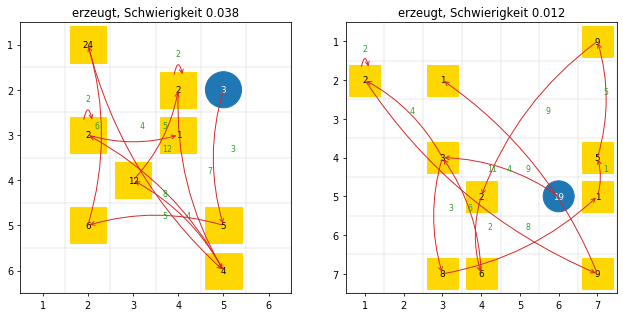

In [ ]:
def schwierige_situation(seed, n, k, versuche=30):
    zufall = random.Random(seed)
    beste = None
    erzeugt = 0
    while erzeugt < versuche:
        e = erzeuge(zufall, n, k)
        if e is None:
            continue
        erzeugt += 1
        situation, zuege = e
        wert = schwierigkeit(*situation)
        if beste is None or wert < beste[0]:
            beste = (wert, situation, zuege)
    return beste


erzeugte = []
for seed, n, k in [(1, 6, 8), (1, 7, 10)]:
    wert, situation, zuege_erzeuger = schwierige_situation(seed, n, k)
    n, start, bord, batterien = situation
    print('%d x %d mit %d Batterien, Schwierigkeit %.3f' % (n, n, k, wert))
    print('Datei:', n, '/', '%d,%d,%d' % (start[0], start[1], bord), '/', len(batterien), '/',
          ' '.join('%d,%d,%d' % (f[0], f[1], batterien[f]) for f in batterien))
    ergebnis, zuege, aufrufe = loese_v3(n, start, bord, batterien, GRENZE)
    print('Unsere Suche:', ergebnis, '(%d Aufrufe)' % aufrufe)
    print('Lösung des Erzeugers:')
    schritte = zeige_loesung(n, start, bord, batterien, zuege_erzeuger, zeilen=20)
    erzeugte.append((situation, zuege_erzeuger, wert, ergebnis, aufrufe, schritte))
    print()

fig, achsen = plt.subplots(1, 2, figsize=(11, 5.5))
for i in range(2):
    situation, zuege, wert, ergebnis, aufrufe, schritte = erzeugte[i]
    zeichne(achsen[i], *situation, zuege, titel='erzeugt, Schwierigkeit %.3f' % wert)
plt.show()

Beide erzeugten Situationen sind nach unserem Maß schwieriger als das Beispiel vom Aufgabenblatt (0,038 und 0,012 gegenüber 0,05), und
in beiden Lösungen des Erzeugers wird mehrfach auf dasselbe Feld zurückgekehrt (bei der ersten zum Beispiel in Zug 7 und Zug 10: hinaus
und wieder hinein, um eine Batterie zu leeren). Interessant ist der Vergleich mit unserer Suche: Die erste Situation löst sie mit 11
Aufrufen, die zweite schafft sie in 100000 Aufrufen nicht. Lösbar ist die zweite trotzdem, das zeigt die Lösung des Erzeugers, die der
Schiedsrichter bestätigt. Was für einen ratenden Menschen schwer ist und was für einen Computer, der systematisch alles durchprobiert,
ist eben nicht dasselbe.

Typisch für dieses Erzeugungsverfahren sind große Ladungen (hier bis 24), weil manche Batterie bei mehreren Zügen getragen wird; darauf
weisen auch die Lösungshinweise hin. Wer eine bestimmte Schwierigkeit haben möchte, kann so lange erzeugen, bis der Wert unter einer
vorgegebenen Grenze liegt; dann ist die Schwierigkeit ein Eingabewert des Erzeugers.

## Für Neugierige: nur kürzeste und längste Wege?

Die Lösungshinweise schlagen vor, bei jedem Zug nur **zwei** Längen zu probieren: den kürzesten Weg und den längsten, den die Ladung
erlaubt (danach ist die abgelegte Batterie leer oder hat noch 1). Fast immer gibt es dann noch eine Lösung, wenn es überhaupt eine gibt
(Lemma in Abschnitt 1.2.3.2). `loese_v4` ist `loese_v3` mit dieser Einschränkung.

In [ ]:
def loese_v4(n, start, bord, batterien, grenze):
    ladung = dict(batterien)
    bis = max([bord] + list(batterien.values()))
    laengen = alle_laengen(n, start, batterien, bis)
    zuege = []
    aufrufe = [0]
    gescheitert = set()

    def suche(feld, bord):
        aufrufe[0] += 1
        if aufrufe[0] > grenze:
            raise GrenzeErreicht()
        if max(ladung.values(), default=0) == 0:
            return endlauf_moeglich(feld, bord, n, batterien)
        lage = (feld, bord, tuple(ladung.values()))
        if lage in gescheitert:
            return False
        if not alle_erreichbar(feld, bord, ladung):
            gescheitert.add(lage)
            return False
        moeglich = []
        for t in laengen[feld]:
            if ladung[t] > 0:
                ds = [d for d in laengen[feld][t] if d <= bord]
                if len(ds) > 2:
                    ds = [ds[0], ds[-1]]              # neu: nur kürzester und längster Weg
                for d in ds:
                    moeglich.append((bord - d, d, t))
        moeglich.sort()
        for rest, d, t in moeglich:
            alt = ladung[t]
            ladung[t] = rest
            zuege.append((feld, t, d))
            if suche(t, alt):
                return True
            zuege.pop()
            ladung[t] = alt
        gescheitert.add(lage)
        return False

    try:
        ergebnis = suche(start, bord)
    except GrenzeErreicht:
        ergebnis = None
    return ergebnis, zuege, aufrufe[0]


def loese(n, start, bord, batterien, grenze):
    return loese_v4(n, start, bord, batterien, grenze)


ergebnisse_v4 = teste([0, 1, 3, 4, 5])

zufall = random.Random(1)
gleich = 0
for _ in range(1000):
    n = zufall.randint(2, 4)
    situation = zufallssituation(zufall, n, zufall.randint(1, min(5, n * n - 1)), 5)
    if loese_v3(*situation, 10 * GRENZE)[0] == loese_v4(*situation, 10 * GRENZE)[0]:
        gleich += 1
print('Gleiches Ergebnis bei', gleich, 'von 1000 Situationen der Probe')

stromrallye0.txt: lösbar, 4 Züge, 10 Aufrufe
stromrallye1.txt: lösbar, 99 Züge, 100 Aufrufe
stromrallye3.txt: nicht lösbar, 22 Aufrufe
stromrallye4.txt: lösbar, 0 Züge, 1 Aufrufe
stromrallye5.txt: nicht lösbar, 2923 Aufrufe
Gleiches Ergebnis bei 1000 von 1000 Situationen der Probe


Bei `stromrallye5.txt` braucht `loese_v4` nur 2923 statt 6316 Aufrufe, und bei allen 1000 Situationen der Probe kommt dasselbe heraus.
Aber „fast immer“ heißt nicht „immer“. Abbildung 1.1 der Hinweise zeigt eine Situation, in der der Roboter mit genau der richtigen
Restladung in einen engen Bereich hineingehen muss. Ein kleines Beispiel dieser Art haben wir beim Erstellen des Notebooks mit
Zufallssituationen gefunden, in denen auch leere Batterien vorkommen (sie wirken wie Mauern):

In [ ]:
gegenbeispiel = (3, (3, 2), 9, {(1, 1): 1, (3, 1): 0, (1, 2): 1, (2, 2): 1, (2, 3): 1})
print('Schrittweise Suche:', loesbar_schrittweise(*gegenbeispiel))
print('loese_v4:', loese_v4(*gegenbeispiel, GRENZE)[0])
ergebnis_g, zuege_g, aufrufe_g = loese_v3(*gegenbeispiel, GRENZE)
print('loese_v3:', ergebnis_g)
schritte_g = zeige_loesung(*gegenbeispiel, zuege_g)

Schrittweise Suche: True
loese_v4: False
loese_v3: True
Zug 1: (3, 2) -> (2, 2), Länge 7: UOUOUOL, legt 2 ab, nimmt 1 auf
Zug 2: (2, 2) -> (2, 3), Länge 1: U, legt 0 ab, nimmt 1 auf
Zug 3: (2, 3) -> (2, 2), Länge 1: O, legt 0 ab, nimmt 2 auf
Zug 4: (2, 2) -> (1, 1), Länge 2: OL, legt 0 ab, nimmt 1 auf
Zug 5: (1, 1) -> (1, 2), Länge 1: U, legt 0 ab, nimmt 1 auf
Endlauf, Länge 1: O
Schrittfolge: UOUOUOLUOOLUO
13 Schritte, Schiedsrichter: gelöst


Ein 3 × 3-Brett, der Roboter steht auf `(3, 2)` mit Ladung 9, die leere Batterie auf `(3, 1)` ist eine Mauer. Es gibt genau vier
Zugfolgen, die zum Ziel führen (beim Erstellen durch Aufzählen geprüft), und alle beginnen mit einem **mittellangen** Weg: zu `(2, 2)`
mit 5 oder 7 Schritten oder zu `(2, 3)` mit 6 Schritten. Mit dem kürzesten Weg bleibt zu viel Ladung liegen, mit dem längsten zu wenig.
`loese_v3` probiert alle Längen und findet die Lösung mit 7 Schritten (dreimal hinunter und zurück, dann nach links). Die Hinweise erkennen solche Fälle mit einer zusätzlichen Prüfung und probieren dann alle Längen. Wir probieren einfach immer
alle Längen; bei den Beispielen ist das schnell genug.

**Weitere Ideen aus den Lösungshinweisen**
- **Schwer im Allgemeinen:** Bei lauter Batterien mit Ladung 1 (wie `stromrallye1.txt`) muss der Roboter jedes Feld genau einmal
  besuchen. Das ist die Suche nach einem *Hamiltonpfad* in einem Gittergraphen, und dafür kennt man kein schnelles Verfahren. Mehr als
  eine geschickte Suche kann man also nicht erwarten.
- **Zufällige Neustarts:** Eine Tiefensuche, die sich am Anfang falsch entschieden hat, steckt lange in einem aussichtslosen Teilbaum.
  Die Hinweise starten die Suche deshalb immer wieder mit zufälliger Reihenfolge neu und lassen daneben eine vollständige Suche laufen,
  die auch Unlösbarkeit beweisen kann.
- **Rechtecke voller gleicher Batterien:** Für rechteckige Bereiche (und einige andere Formen) kann man Hamiltonpfade direkt angeben.
  So ließe sich `stromrallye2.txt` automatisch lösen; die Spirale aus Schritt 8 ist genau so ein Pfad.

## Zum Schluss: Stromrallye mit MiniZinc

Kann MiniZinc die Aufgabe lösen? Hier hilft die Beobachtung aus der Idee: Jede Lösung hat genau `T` Schritte, so viel Ladung ist am
Anfang da. Wir beschreiben deshalb einfach **jeden Schritt** mit Variablen: das Feld `(x[t], y[t])` des Roboters nach `t` Schritten, die
Ladung `bord[t]` der Bordbatterie und für jedes Batteriefeld `f` die Ladung `liegt[f, t]` der Batterie, die dort liegt.

- Vor jedem Schritt muss die Bordbatterie noch Ladung haben, und der Roboter geht genau ein Feld weit.
- `auf[f]` sagt, ob der Roboter nach Schritt `t` auf Batteriefeld `f` steht. Dann wird getauscht: Auf `f` liegt jetzt die alte
  Bordbatterie mit einer Einheit weniger, und die Bordladung ist die Ladung, die vorher auf `f` lag. Sonst bleibt `liegt` gleich, und
  die Bordladung sinkt um 1.
- Dass am Ende alles leer ist, muss man nicht verlangen: Jeder Schritt verbraucht genau eine Einheit, nach `T` Schritten ist also keine
  mehr da.

Neu gegenüber den Arbeitsblättern sind `let { ... } in` (Hilfsvariablen nur für diese Bedingung), `if … then … else … endif` mit
Bedingungen in den Zweigen und `exists` (das Gegenstück zu `forall`: mindestens eine Bedingung stimmt). `fix(x[t])` in der Ausgabe ist
der Wert der Variablen in der Lösung; daraus macht die Ausgabe die Buchstaben R, L, U, O.
```minizinc
int: n;                                    % Brettgröße
int: k;                                    % Zahl der Ersatzbatterien
array[1..k] of int: bx;                    % Feld der Batterie f
array[1..k] of int: by;
array[1..k] of int: anfang;                % Anfangsladungen
int: sx;
int: sy;
int: q0;                                   % Roboter und Bordbatterie
int: T = q0 + sum(anfang);                 % so viele Schritte hat jede Lösung
int: L = max([q0] ++ anfang);

array[0..T] of var 1..n: x;                % Feld des Roboters nach t Schritten
array[0..T] of var 1..n: y;
array[0..T] of var 0..L: bord;             % Ladung der Bordbatterie nach t Schritten
array[1..k, 0..T] of var 0..L: liegt;      % Ladung der Batterie, die auf Feld f liegt

constraint x[0] = sx /\ y[0] = sy /\ bord[0] = q0;
constraint forall(f in 1..k)(liegt[f, 0] = anfang[f]);

constraint forall(t in 1..T)(
  bord[t-1] >= 1 /\
  abs(x[t] - x[t-1]) + abs(y[t] - y[t-1]) = 1 /\
  let { array[1..k] of var bool: auf = [x[t] = bx[f] /\ y[t] = by[f] | f in 1..k] } in
  forall(f in 1..k)(
    if auf[f] then liegt[f, t] = bord[t-1] - 1 /\ bord[t] = liegt[f, t-1]
    else liegt[f, t] = liegt[f, t-1] endif) /\
  (not exists(f in 1..k)(auf[f]) -> bord[t] = bord[t-1] - 1)
);

solve satisfy;
output ["Schritte: ", concat([if fix(x[t]) > fix(x[t-1]) then "R" elseif fix(x[t]) < fix(x[t-1]) then "L"
                             elseif fix(y[t]) > fix(y[t-1]) then "U" else "O" endif | t in 1..T]), "\n"];
```

Die Datendatei erzeugt `als_dzn` aus einer eingelesenen Situation.

In [ ]:
def als_dzn(n, start, bord, batterien):
    felder = list(batterien)
    zeilen = ['n = %d;' % n, 'k = %d;' % len(felder),
              'bx = %s;' % [f[0] for f in felder], 'by = %s;' % [f[1] for f in felder],
              'anfang = %s;' % [batterien[f] for f in felder],
              'sx = %d;' % start[0], 'sy = %d;' % start[1], 'q0 = %d;' % bord]
    return '\n'.join(zeilen)


print(als_dzn(n0, start0, bord0, batterien0))

n = 5;
k = 3;
bx = [5, 1, 5];
by = [1, 2, 4];
anfang = [3, 2, 3];
sx = 3;
sy = 5;
q0 = 9;


**`stromrallye0.txt`** (Chuffed):

**Ausgabe:**

```
Schritte: RROOOOUUUOLOLLLRR
----------
```

Der Schiedsrichter `spiele` bestätigt diese Schrittfolge. Chuffed findet sie über einen etwas anderen Weg als unsere Suche, aber mit
denselben Zügen. So sieht es bei allen Beispielen aus (gemessen beim Erstellen dieses Notebooks mit Zeitlimit 60 Sekunden; bei
`stromrallye5.txt` zusätzlich mit 5 Minuten für Chuffed und CP-SAT):

| Beispiel | Schritte `T` | Gecode | Chuffed | CP-SAT |
|----------|--------------|--------|---------|--------|
| `stromrallye0.txt` | 17 | Lösung nach einigen Sekunden | Lösung sofort | Lösung nach etwa 1 Sekunde |
| `stromrallye1.txt` | 100 | Lösung nach einigen Sekunden | keine Lösung | Lösung nach etwa 20 Sekunden |
| `stromrallye2.txt` | 242 | keine Lösung | keine Lösung | keine Lösung |
| `stromrallye3.txt` | 28 | keine Entscheidung | **nicht lösbar**, sofort bewiesen | **nicht lösbar** nach etwa 25 Sekunden |
| `stromrallye4.txt` | 20 | Lösung sofort | Lösung sofort | Lösung sofort |
| `stromrallye5.txt` | 90 | keine Entscheidung | keine Entscheidung, auch nicht in 5 Minuten | keine Entscheidung, auch nicht in 5 Minuten |

Beim Erzeugen des Notebooks laufen die Fälle 0, 3 und 4 mit Chuffed und Fall 1 mit Gecode; jede gefundene Schrittfolge wird vom
Schiedsrichter geprüft, und bei `stromrallye3.txt` muss `=====UNSATISFIABLE=====` herauskommen.

Das Schrittmodell ist schnell aufgeschrieben und braucht nur die Beobachtung „genau `T` Schritte“. Es weiß aber nichts von Zügen,
Weglängen oder unerreichbaren Batterien. Dass Chuffed `stromrallye3.txt` trotzdem sofort widerlegt, liegt an seinem Lernen aus
Konflikten: Er merkt sich die Gründe für Sackgassen, ähnlich wie unsere Menge `gescheitert`, nur allgemeiner. Bei `stromrallye5.txt`
(90 Schritte, 34 Batterien) reicht das nicht; unsere Suche mit der Erreichbarkeitsprüfung braucht dort 6316 Aufrufe. Die
Spirale von `stromrallye2.txt` mit 242 Schritten findet keiner der Solver. Für diese Aufgabe ist die eigene Suche also das bessere
Werkzeug, MiniZinc eignet sich aber gut, um kleine Situationen unabhängig nachzuprüfen.